# Movilidad CDMX

Este módulo transforma los datos disponibles en **preguntas de investigación descriptivas**. Cada visualización responde una pregunta concreta y se acompaña de una interpretación basada en los datos, su relevancia y sus limitaciones.

**Fuentes**
- `Afluencia Diaria del Metro (Desglosada.csv)`
- `Afluencia Diaria del Metrobús (Desglosada).csv`
- `Afluencia Prelimiar en Transporte Publico (histórico).csv`
- `Ingresos del Sistema de Transportte Colectivo Metro.csv`


## Objetivos

1. Identificar tendencias de largo plazo y estacionalidad.
2. Describir diferencias por día, hora, género y edad.
3. Analizar distribución y capacidad de infraestructura.
4. Detectar estaciones, rutas y desequilibrios operativos en enero de 2026.
5. Analizar duración sin dejar que registros temporalmente anómalos distorsionen las métricas.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
REQUIRED_FILES = (
    "Afluencia Diaria del Metro (Desglosada).csv",
    "Afluencia Diaria del Metrobús (Desglosada).csv",
    "Afluencia Preliminar en Transporte Publico (histórico).csv",
    "Diccionario Afluencia Desglosada - MB.csv",
    "Diccionario de datos (Afluencia desglosada).csv",
    "Diccionario de datos ingresos STCM.xlsx",
    "Ingresos del Sistema de Transporte Colectivo Metro.csv",
    "Viajes diarios del sistema Ecobici.csv",
    "Viajes Ecobici 2026-01.csv",
    "Viajes mensuales desglosados del sistema Ecobici.csv",
)

def localizar_datos() -> Path:
    """Devuelve la carpeta datasets/ de Movilidad-Urbana-del-Sistema-de-Transporte-CDMX o indica cómo prepararla."""
    candidatos = []
    definida = os.environ.get("MOVILIDAD_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
            base / "Datasets",
            base.parent / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
        ])

    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in REQUIRED_FILES):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Movilidad-Urbana. Ejecuta 'git clone "
        "https://github.com/Juan-Gallegos7/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX' en la "
        "carpeta del curso y coloca este notebook en una carpeta hermana "
        "del repositorio; o establece MOVILIDAD_DATA_DIR con la ruta a datasets/."
    )


DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: C:\Users\jgallegos\Desktop\Proyecto 2\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX\Datasets


In [3]:
ruta = Path("C:/Users/ricar/iCloudDrive/Diplomado_Modelos_Est_y_Mat/Modulo_1/Proyecto/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX/Datasets")
for nombre in REQUIRED_FILES:
    existe = ( ruta / nombre).is_file()
    print(nombre, "->", existe)

Afluencia Diaria del Metro (Desglosada).csv -> False
Afluencia Diaria del Metrobús (Desglosada).csv -> False
Afluencia Preliminar en Transporte Publico (histórico).csv -> False
Diccionario Afluencia Desglosada - MB.csv -> False
Diccionario de datos (Afluencia desglosada).csv -> False
Diccionario de datos ingresos STCM.xlsx -> False
Ingresos del Sistema de Transporte Colectivo Metro.csv -> False
Viajes diarios del sistema Ecobici.csv -> False
Viajes Ecobici 2026-01.csv -> False
Viajes mensuales desglosados del sistema Ecobici.csv -> False


In [4]:

import chardet

with open(
    DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv",
    "rb"
) as f:
    resultado = chardet.detect(f.read(100000))

print(resultado)

{'encoding': 'utf-8', 'confidence': 0.9023036, 'language': 'pt', 'mime_type': 'text/plain'}


In [5]:
Afluencia_Metro = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv")
Afluencia_Metrobus = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metrobús (Desglosada).csv")
Afluencia_TP_historico = pd.read_csv(DATA_DIR / "Afluencia Preliminar en Transporte Publico (histórico).csv")
Ingresos_SCTM = pd.read_csv(DATA_DIR / "Ingresos del Sistema de Transporte Colectivo Metro.csv")
#Dic_Afluencia = pd.read_csv(DATA_DIR / "Diccionario Afluencia Desglosada - MB.csv", encoding="ISO-8859-1")
#Dic_datos_Afluencia = pd.read_csv(DATA_DIR / "Diccionario de datos (Afluencia desglosada).csv", encoding="ISO-8859-1")
Dic_ingresos_SCTM = pd.read_excel(DATA_DIR / "Diccionario de datos ingresos STCM.xlsx")
#Viajes_Ecobici_202601 = pd.read_csv(DATA_DIR / "Viajes Ecobico 2026-01.csv")
#Viajes_Ecobici_mensual = pd.read_csv(DATA_DIR / "Viajes mensuales desglosados del sistema Ecobici.csv")

for nombre, tabla in {
    "Afluencia_Metro": Afluencia_Metro,
    "Afluencia_Metrobus": Afluencia_Metrobus,
    "Afluencia_TP_historico": Afluencia_TP_historico,
    #"Dic_Afluencia": Dic_Afluencia,
    #"Dic_datos_Afluencia": Dic_datos_Afluencia,
    "Dic_ingresos_SCTM": Dic_ingresos_SCTM,
    "Ingresos_SCTM": Ingresos_SCTM,
    #"Viajes_Ecobici_202601": Viajes_Ecobici_202601,
    #"Viajes_Ecobici_mensual": Viajes_Ecobici_mensual,
}.items():
    print(f"{nombre:12s}: {len(tabla):>8,} filas × {tabla.shape[1]:>2} columnas")

display(Afluencia_Metro.head(3))
display(Afluencia_Metrobus.head(3))
display(Afluencia_TP_historico.head(3))
#display(Dic_Afluencia.head())
#display(Dic_datos_Afluencia.head())
display(Dic_ingresos_SCTM.head())
display(Ingresos_SCTM.head(3))
#display(Viajes_Ecobici_202601.head(3))
#display(Viajes_Ecobici_mensual.head(3))

Afluencia_Metro: 1,227,915 filas ×  7 columnas
Afluencia_Metrobus:   29,386 filas ×  6 columnas
Afluencia_TP_historico:   18,714 filas ×  8 columnas
Dic_ingresos_SCTM:       14 filas ×  3 columnas
Ingresos_SCTM:  159,948 filas ×  4 columnas


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia
0,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Boleto,1848
1,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Prepago,790
2,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Gratuidad,325


,fecha,mes,anio,linea,tipo_pago,afluencia
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0


,id,organismo,linea_servicio,dia,fecha,afluencia_tarjeta,afluencia_boleto,afluencia_total_preliminar
0,1,Ecobici,NaN,Domingo,2020-03-01,NaN,NaN,"11,238"
1,2,Ecobici,NaN,Lunes,2020-03-02,NaN,NaN,"29,475"
2,3,Ecobici,NaN,Martes,2020-03-03,NaN,NaN,"31,855"


,Variable,Descripción Variable,Etiqueta de Datos Abiertos
0,Fecha,Indica el día en el que se recibió este ingreso.,FECHA
1,Tipo de ingreso,Campo que especifíca si el ingreso fue por ven...,TIPO_INGRESO
2,Línea 1,Indica los ingresos que recibió la ciudad para...,LINEA_1
3,Línea 2,Indica los ingresos que recibió la ciudad para...,LINEA_2
4,Línea 3,Indica los ingresos que recibió la ciudad para...,LINEA_3


,fecha,tipo_ingreso,linea,ingreso
0,2012-01-01,Boletos,Línea 1,648825.0
1,2012-01-01,Boletos,Línea 2,657120.0
2,2012-01-01,Boletos,Línea 3,466803.0


In [6]:
display(Afluencia_Metro.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Metro"))
display(Afluencia_Metrobus.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Metrobus"))
display(Afluencia_TP_historico.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Historico"))

,Faltantes Metro
fecha,0
mes,0
anio,0
linea,0
estacion,0
tipo_pago,0
afluencia,0


,Faltantes Metrobus
fecha,0
mes,0
anio,0
linea,0
tipo_pago,0
afluencia,0


,Faltantes Historico
afluencia_tarjeta,16027
afluencia_boleto,15116
linea_servicio,489
afluencia_total_preliminar,202
dia,0
organismo,0
id,0
fecha,0


Dado que los valores de la variable linea están incorrectos en formato, es necesario corregir la etiqueta "LÃ­nea" por "Linea", para mantener consistencia.

In [7]:
Afluencia_Metro["linea"]=Afluencia_Metro["linea"].str.replace("LÃ­nea","Linea", regex=False)

In [8]:
print("Registros por línea (Metro): ", Afluencia_Metro.groupby("linea").size())
print("Registros por mes (Metro): ", Afluencia_Metro.groupby("mes").size())
print("Registros por mes (Año): ", Afluencia_Metro.groupby("anio").size())
print("Registros por mes (Estacion): ", Afluencia_Metro.groupby("estacion").size())
print("Registros por mes (tipo_pago): ", Afluencia_Metro.groupby("tipo_pago").size())

Registros por línea (Metro):  linea
Linea 1     125940
Linea 12    125940
Linea 2     151128
Linea 3     132237
Linea 4      62970
Linea 5      81861
Linea 6      69267
Linea 7      88158
Linea 8     119643
Linea 9      75564
Linea A      62970
Linea B     132237
dtype: int64
Registros por mes (Metro):  mes
Abril         105300
Agosto        108810
Diciembre      90675
Enero         108810
Febrero        98865
Julio         108810
Junio         105300
Marzo         108810
Mayo          108810
Noviembre      87750
Octubre        90675
Septiembre    105300
dtype: int64
Registros por mes (Año):  anio
2021    213525
2022    213525
2023    213525
2024    214110
2025    213525
2026    159705
dtype: int64
Registros por mes (Estacion):  estacion
Acatitla                 6297
Aculco                   6297
AgrÃ­cola Oriental       6297
Allende                  6297
Apatlaco                 6297
                        ...  
Xola                     6297
Zapata                  12594
ZapotitlÃ¡n 

Dado que los valores de la variable linea están incorrectos en formato, es necesario corregir la etiqueta "Línea" por "Linea", para mantener consistencia.

In [9]:
Afluencia_Metrobus["linea"]=Afluencia_Metrobus["linea"].str.replace("Línea","Linea", regex=False)

In [10]:
print("Registros por línea (Metrobus): ", Afluencia_Metrobus.groupby("linea").size())
print("Registros por mes (Metrobus): ", Afluencia_Metrobus.groupby("mes").size())
print("Registros por Año (Metrobus): ", Afluencia_Metrobus.groupby("anio").size())
print("Registros por Tipo pago (Metrobus): ", Afluencia_Metrobus.groupby("tipo_pago").size())

Registros por línea (Metrobus):  linea
Linea 1    3468
Linea 2    3468
Linea 3    3468
Linea 4    3468
Linea 5    3468
Linea 6    3468
Linea 7    3468
linea 1     730
linea 2     730
linea 3     730
linea 4     730
linea 5     730
linea 6     730
linea 7     730
dtype: int64
Registros por mes (Metrobus):  mes
Abril         2520
Agosto        2604
Diciembre     2170
Enero         2604
Febrero       2366
Julio         2604
Junio         2520
Marzo         2604
Mayo          2604
Noviembre     2100
Octubre       2170
Septiembre    2520
dtype: int64
Registros por Año (Metrobus):  anio
2021    5110
2022    5110
2023    5110
2024    5124
2025    5110
2026    3822
dtype: int64
Registros por Tipo pago (Metrobus):  tipo_pago
Gratuidad    14693
Prepago      14693
dtype: int64


In [11]:
print("Registros por organismo (Metro): ", Afluencia_TP_historico.groupby("organismo").size())
print("Registros por servicio (Metro): ", Afluencia_TP_historico.groupby("linea_servicio").size())
print("Registros por dia (Año): ", Afluencia_TP_historico.groupby("dia").size())

Registros por organismo (Metro):  organismo
Ecobici             489
Metrobús           3461
RTP                3671
STC                5868
STE-Cablebús        121
STE-Tren Ligero     489
STE-Trolebús       4126
Suburbano           489
dtype: int64
Registros por servicio (Metro):  linea_servicio
Atenea                                                489
Eco Atenea                                            489
Ecobús                                                489
Expreso                                               489
Expreso Directo                                       489
L1                                                   1467
L1 Campos Revolución-Tlalpexco                        121
L1 Eje Central                                        489
L12                                                   489
L2                                                    978
L2 Eje 2 sur                                          489
L3                                                    978
L3 Eje 

# Visualizaciones

Preparación de los datos

In [12]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Markdown, display

# Copias analíticas: las tablas originales cargadas al inicio permanecen intactas.
metro = Afluencia_Metro.copy()
metrobus = Afluencia_Metrobus.copy()
historico = Afluencia_TP_historico.copy()
ingresos = Ingresos_SCTM.copy()

# Tipos y variables temporales comunes.
for df in (metro, metrobus):
    df['fecha'] = pd.to_datetime(df['fecha'], errors='coerce')
    df['afluencia'] = pd.to_numeric(df['afluencia'], errors='coerce')
    df['anio_calc'] = df['fecha'].dt.year
    df['mes_calc'] = df['fecha'].dt.to_period('M').dt.to_timestamp()
    # Homogeneiza Linea/Línea/linea sin alterar el identificador de la línea.
    df['linea'] = (df['linea'].astype('string').str.strip()
                   .str.replace(r'(?i)^l[ií]nea\s*', 'Linea ', regex=True))

historico['fecha'] = pd.to_datetime(historico['fecha'], errors='coerce')
historico['afluencia_total_num'] = pd.to_numeric(
    historico['afluencia_total_preliminar'].astype('string').str.replace(',', '', regex=False),
    errors='coerce'
)
historico['mes_calc'] = historico['fecha'].dt.to_period('M').dt.to_timestamp()

ingresos['fecha'] = pd.to_datetime(ingresos['fecha'], errors='coerce')
ingresos['ingreso'] = pd.to_numeric(ingresos['ingreso'], errors='coerce')
ingresos['mes_calc'] = ingresos['fecha'].dt.to_period('M').dt.to_timestamp()

print(f"Cobertura Metro: {metro['fecha'].min().date()} a {metro['fecha'].max().date()}")
print(f"Cobertura Metrobús: {metrobus['fecha'].min().date()} a {metrobus['fecha'].max().date()}")
print(f"Cobertura ingresos STC: {ingresos['fecha'].min().date()} a {ingresos['fecha'].max().date()}")


Cobertura Metro: 2021-01-01 a 2026-09-30
Cobertura Metrobús: 2021-01-01 a 2026-09-30
Cobertura ingresos STC: 2012-01-01 a 2023-07-31


## 1. Líneas con mayor afluencia diaria

### Pregunta 1
**¿Qué líneas concentran la mayor afluencia diaria promedio en cada sistema?**

Se utiliza el **promedio diario por línea** en vez del acumulado total. Así se reduce el sesgo que introducirían diferencias en la cantidad de días disponibles por línea o año.


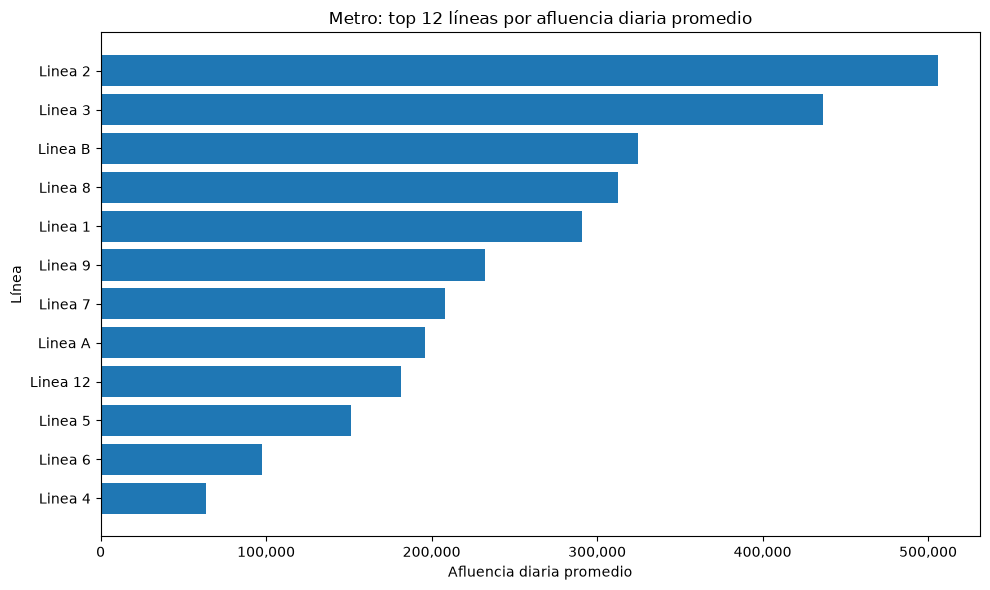

**Interpretación — Metro.** **Linea 2** registra la mayor afluencia diaria promedio: **506,059** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

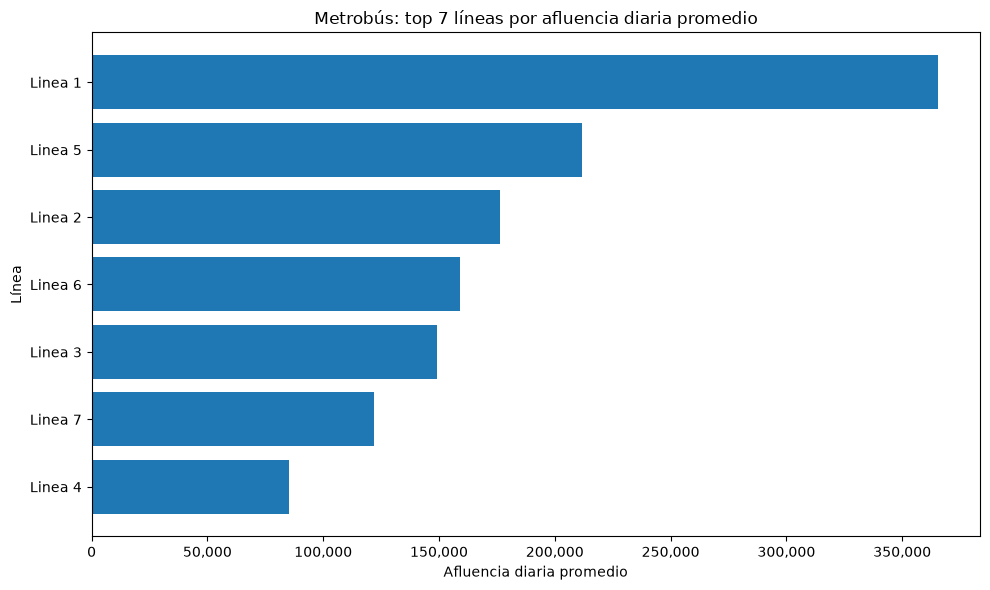

**Interpretación — Metrobús.** **Linea 1** registra la mayor afluencia diaria promedio: **365,323** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

In [13]:
def ranking_lineas(df, sistema, top=12):
    diario = df.groupby(['fecha', 'linea'], as_index=False)['afluencia'].sum()
    ranking = (diario.groupby('linea')['afluencia']
                     .agg(promedio='mean', mediana='median', dias='count')
                     .sort_values('promedio', ascending=True)
                     .tail(top))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(ranking.index, ranking['promedio'])
    ax.set_title(f'{sistema}: top {min(top, len(ranking))} líneas por afluencia diaria promedio')
    ax.set_xlabel('Afluencia diaria promedio')
    ax.set_ylabel('Línea')
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    plt.tight_layout()
    plt.show()

    lider = ranking['promedio'].idxmax()
    display(Markdown(
        f"**Interpretación — {sistema}.** **{lider}** registra la mayor afluencia diaria promedio: "
        f"**{ranking.loc[lider, 'promedio']:,.0f}** pasajeros.  \n"
        "**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  \n"
        "**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación."
    ))
    return ranking.sort_values('promedio', ascending=False)

rank_metro = ranking_lineas(metro, 'Metro')
rank_mb = ranking_lineas(metrobus, 'Metrobús')


## 2. Evolución mensual comparable entre Metro y Metrobús

### Pregunta 2
**¿Metro y Metrobús muestran patrones temporales semejantes en su afluencia?**

Como ambos sistemas operan en escalas muy diferentes, se construye un **índice base 100** durante el periodo común. La figura compara cambios relativos y no niveles absolutos de pasajeros.


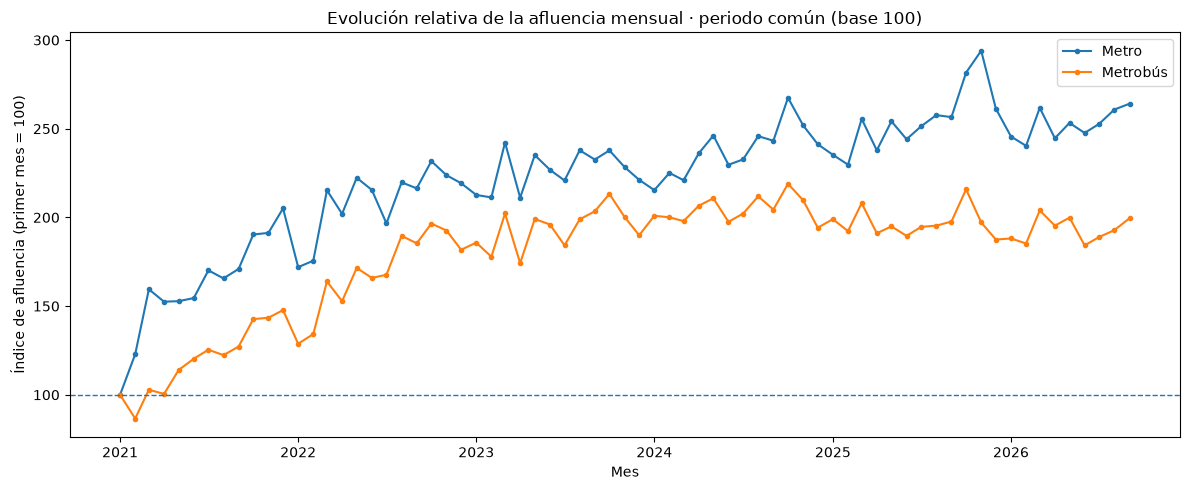

**Interpretación.** Entre **2021-01** y **2026-09**, Metro termina **+164.1%** respecto del primer mes y Metrobús **+99.5%**. La correlación mensual entre ambos volúmenes es **r = 0.912**.  
**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  
**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad.

In [14]:
def serie_mensual(df, nombre):
    return (df.groupby('mes_calc', as_index=False)['afluencia'].sum()
              .rename(columns={'afluencia': nombre}))

metro_mes = serie_mensual(metro, 'Metro')
mb_mes = serie_mensual(metrobus, 'Metrobús')
comparacion = metro_mes.merge(mb_mes, on='mes_calc', how='inner').sort_values('mes_calc').dropna()

for col in ['Metro', 'Metrobús']:
    comparacion[f'{col}_indice'] = comparacion[col] / comparacion[col].iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comparacion['mes_calc'], comparacion['Metro_indice'], marker='o', markersize=3, label='Metro')
ax.plot(comparacion['mes_calc'], comparacion['Metrobús_indice'], marker='o', markersize=3, label='Metrobús')
ax.axhline(100, linewidth=1, linestyle='--')
ax.set_title('Evolución relativa de la afluencia mensual · periodo común (base 100)')
ax.set_xlabel('Mes')
ax.set_ylabel('Índice de afluencia (primer mes = 100)')
ax.legend()
plt.tight_layout()
plt.show()

corr_sistemas = comparacion[['Metro', 'Metrobús']].corr().iloc[0, 1]
delta_metro = comparacion['Metro_indice'].iloc[-1] - 100
delta_mb = comparacion['Metrobús_indice'].iloc[-1] - 100

display(Markdown(
    f"**Interpretación.** Entre **{comparacion['mes_calc'].min():%Y-%m}** y **{comparacion['mes_calc'].max():%Y-%m}**, "
    f"Metro termina **{delta_metro:+.1f}%** respecto del primer mes y Metrobús **{delta_mb:+.1f}%**. "
    f"La correlación mensual entre ambos volúmenes es **r = {corr_sistemas:.3f}**.  \n"
    "**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  \n"
    "**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad."
))


## 3. Concentración de la afluencia por estación del Metro

### Pregunta de investigación 3
**¿Qué tan concentrada está la demanda del Metro en sus estaciones con mayor afluencia?**

La visualización combina el volumen de las principales estaciones con su porcentaje acumulado sobre toda la afluencia observada.


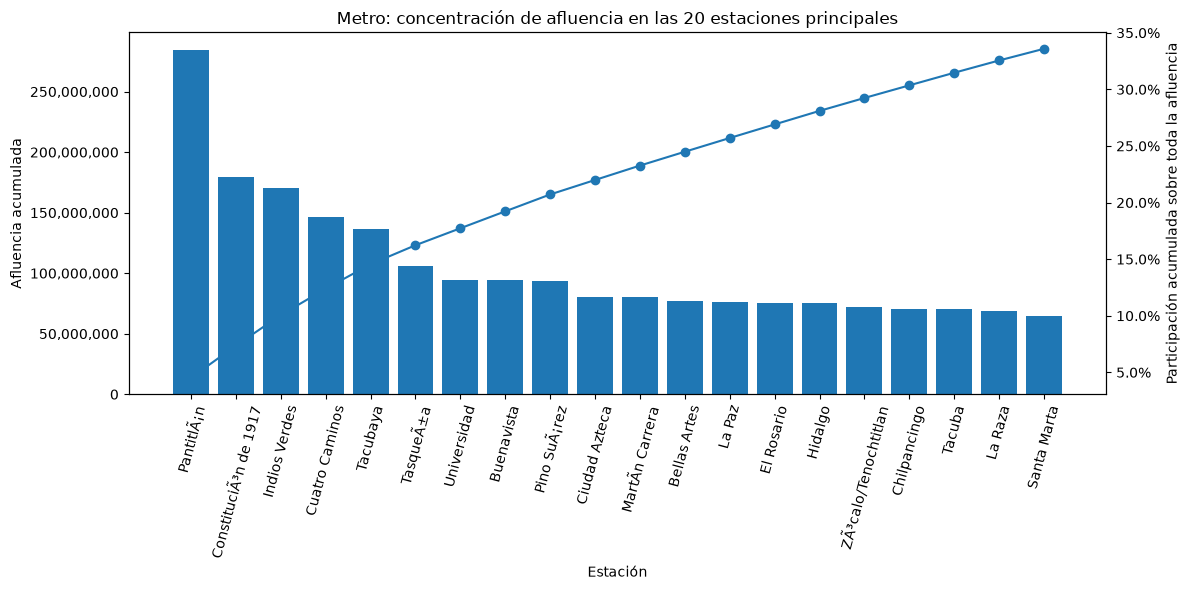

**Interpretación.** Las 20 estaciones con mayor volumen representan **33.6%** de la afluencia registrada. La estación líder es **PantitlÃ¡n**, con **284,750,916** accesos acumulados.  
**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  
**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes.

In [15]:
estaciones_metro = metro.groupby('estacion')['afluencia'].sum().sort_values(ascending=False)
pareto = estaciones_metro.head(20).to_frame('afluencia')
pareto['participacion'] = pareto['afluencia'] / estaciones_metro.sum()
pareto['acumulado'] = pareto['participacion'].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(pareto.index, pareto['afluencia'])
ax1.set_title('Metro: concentración de afluencia en las 20 estaciones principales')
ax1.set_xlabel('Estación')
ax1.set_ylabel('Afluencia acumulada')
ax1.tick_params(axis='x', rotation=75)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(pareto.index, pareto['acumulado'], marker='o')
ax2.set_ylabel('Participación acumulada sobre toda la afluencia')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.grid(False)
plt.tight_layout()
plt.show()

share20 = pareto['participacion'].sum()
lider_est = estaciones_metro.index[0]
display(Markdown(
    f"**Interpretación.** Las 20 estaciones con mayor volumen representan **{share20:.1%}** de la afluencia registrada. "
    f"La estación líder es **{lider_est}**, con **{estaciones_metro.iloc[0]:,.0f}** accesos acumulados.  \n"
    "**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  \n"
    "**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes."
))


## 4. Contexto histórico multimodal del transporte público

### Pregunta de investigación 4
**¿Cómo se comporta la afluencia mensual de los principales organismos de transporte en el histórico disponible?**

Esta sección incorpora la tercera fuente preparada al inicio, `Afluencia_TP_historico`, para ubicar Metro y Metrobús dentro de un contexto de movilidad pública más amplio.


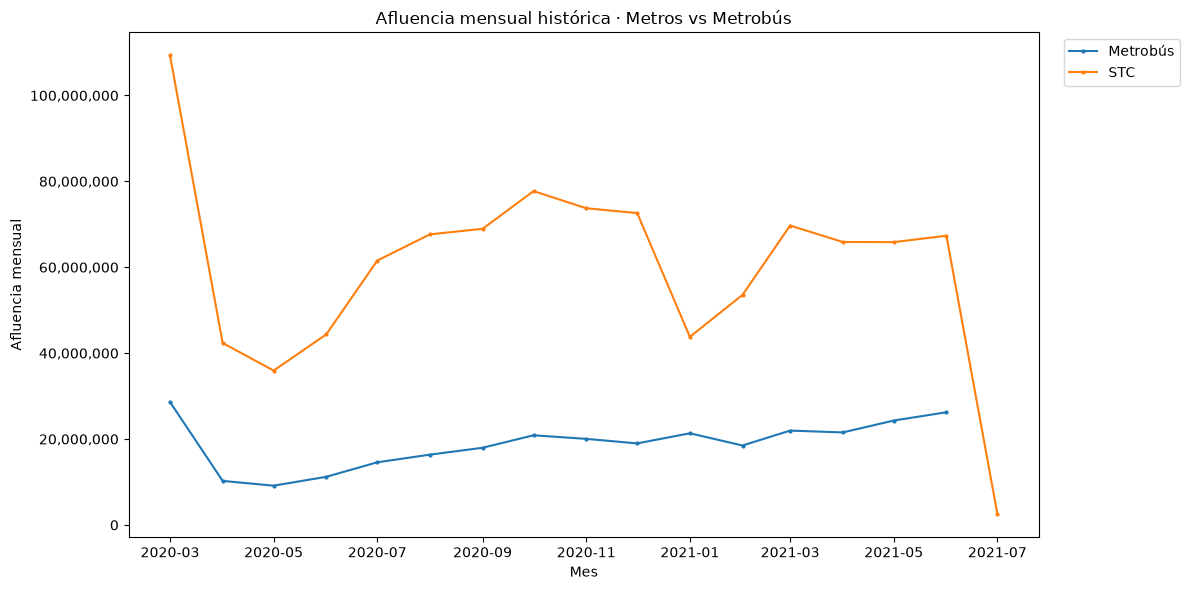

**Interpretación.** En el acumulado del histórico, **STC** registra el mayor volumen entre los organismos disponibles. Las trayectorias mensuales permiten identificar periodos de caída, recuperación o divergencia entre modos.  
**Relevancia.** Evita analizar Metro y Metrobús como sistemas aislados del ecosistema de transporte público.  
**Limitación.** La fuente es preliminar y presenta valores faltantes; además, la cobertura y el nivel de desagregación pueden variar entre organismos.

In [16]:
hist_valid = historico.dropna(subset=['mes_calc', 'organismo', 'afluencia_total_num']).copy()
principales = (hist_valid.groupby('organismo')['afluencia_total_num'].sum()
                        .nlargest(2).index.tolist())
hist_mes = (hist_valid[hist_valid['organismo'].isin(principales)]
            .groupby(['mes_calc', 'organismo'], as_index=False)['afluencia_total_num'].sum())

fig, ax = plt.subplots(figsize=(12, 6))
for organismo, grp in hist_mes.groupby('organismo'):
    ax.plot(grp['mes_calc'], grp['afluencia_total_num'], marker='o', markersize=2, label=organismo)
ax.set_title('Afluencia mensual histórica · Metros vs Metrobús')
ax.set_xlabel('Mes')
ax.set_ylabel('Afluencia mensual')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

lider_hist = (hist_valid.groupby('organismo')['afluencia_total_num'].sum().idxmax())
display(Markdown(
    f"**Interpretación.** En el acumulado del histórico, **{lider_hist}** registra el mayor volumen entre los organismos disponibles. "
    "Las trayectorias mensuales permiten identificar periodos de caída, recuperación o divergencia entre modos.  \n"
    "**Relevancia.** Evita analizar Metro y Metrobús como sistemas aislados del ecosistema de transporte público.  \n"
    "**Limitación.** La fuente es preliminar y presenta valores faltantes; además, la cobertura y el nivel de desagregación pueden variar entre organismos."
))


## 5. Evolución conjunta de afluencia e ingresos del Metro

### Pregunta de investigación 5
**¿Cuál es la evolución conjunta entre la afluencia del Metro y los ingresos reportados por el STC?**

Las dos fuentes no cubren exactamente el mismo periodo. Por ello se agregan por mes y se restringe el análisis al **intervalo temporal común** antes de comparar.


Periodo común: 2021-01 a 2023-07 | 31 meses


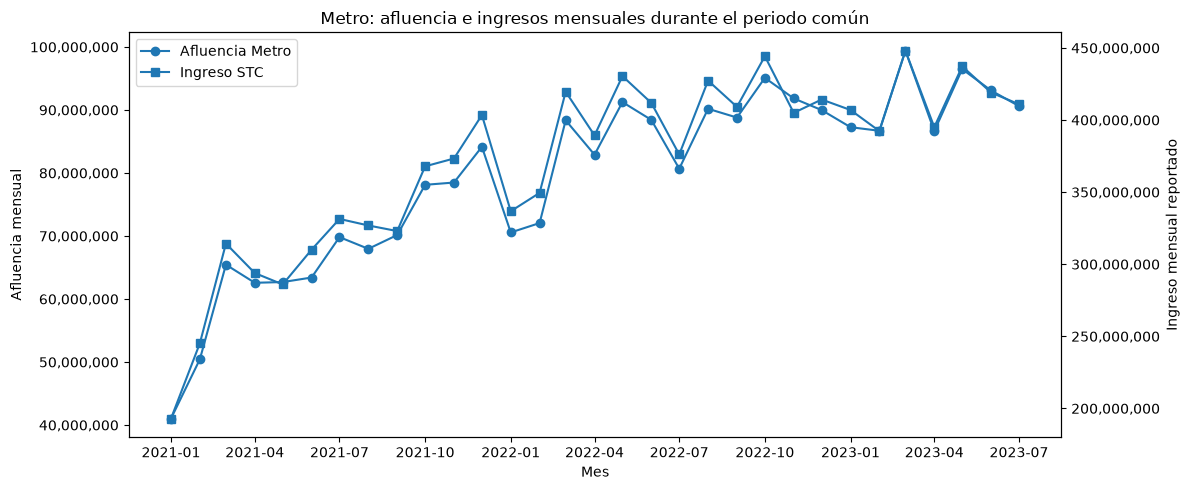

**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es **r = 0.991**.  
**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  
**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación.

In [17]:
metro_ing_mes = (metro.groupby('mes_calc', as_index=False)['afluencia'].sum()
                       .rename(columns={'afluencia': 'afluencia_metro'}))
ingresos_mes = (ingresos.groupby('mes_calc', as_index=False)['ingreso'].sum()
                       .rename(columns={'ingreso': 'ingreso_total'}))
comun = metro_ing_mes.merge(ingresos_mes, on='mes_calc', how='inner').dropna().sort_values('mes_calc')

print(f"Periodo común: {comun['mes_calc'].min():%Y-%m} a {comun['mes_calc'].max():%Y-%m} | {len(comun)} meses")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(comun['mes_calc'], comun['afluencia_metro'], marker='o', label='Afluencia Metro')
ax1.set_xlabel('Mes')
ax1.set_ylabel('Afluencia mensual')
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(comun['mes_calc'], comun['ingreso_total'], marker='s', label='Ingreso STC')
ax2.set_ylabel('Ingreso mensual reportado')
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax2.grid(False)
ax1.set_title('Metro: afluencia e ingresos mensuales durante el periodo común')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout()
plt.show()

corr_total = comun[['afluencia_metro', 'ingreso_total']].corr().iloc[0, 1]
display(Markdown(
    f"**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es "
    f"**r = {corr_total:.3f}**.  \n"
    "**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  \n"
    "**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación."
))
